# ESCM validation — full-resolution comparison with sensory-dependent fading

## Execution backend

Both models use **Brian2 C++ standalone**, compiling native code in separate directories
(`outputs/escm_brian2_cpp/original` and `outputs/escm_brian2_cpp/fading`).
Compilation and executable runtime are reported separately. The original model,
experimental fading model, their simulation timesteps, sensory input, and video
logic are unchanged. A working C++ compiler is required (typically `g++`).

The standalone device is reset between the two distinct builds. OpenMP is disabled
for the reference comparison to avoid introducing parallel-update differences;
C++ execution itself does not require multiple threads. Full-recording runs can
still be expensive and C++ compilation is not guaranteed to succeed for every
custom event rule in every Brian2 version. The notebook has **not** been executed
against Brian2 in this environment.

## Purpose

Run the **original ESCM** and an **explicitly modified ESCM 2.0 candidate** on the exact same full-resolution event stream. Visualize camera events, original output, and fading ESCM 2.0 side by side, with independent, non-overlapping 5-ms bins. The second model is **not** the previously frozen candidate: it deliberately introduces a finite sensory-dependent lifetime for recurrent excitation.

### Why we need a new mechanism

The original ESCM 2.0 rule, `Iexc_post = 8` after *every neuronal spike*, repeatedly refreshes excitation even with no camera input. Exponential decay of `Iexc` between spikes therefore does **not** imply that old activity disappears. For a given neuron, introduce a **sensory-support trace** `support`:

$$\tau_S \frac{d\mathrm{support}}{dt}=-\mathrm{support}, \qquad \mathrm{support} \leftarrow 1\quad \text{when that pixel receives a camera event}.$$

Each output spike now refreshes excitation according to

$$\boxed{I_{exc}\leftarrow W_E \mathrm{support}}.$$

When the camera is silent at a pixel, `support` decays regardless of recurrent spikes. Eventually self-excitation becomes too weak to sustain firing, so old activity can fade. With recurring camera input, `support` is refreshed and the neuron can remain active. This is a *phenomenological sensory-dependent memory mechanism*, not a conventional additive synapse or evidence of biological plausibility.

We set `tau_support = 120 ms` for an initial qualitative test. It is an exploratory timescale, **not fitted or validated**. To observe fading reliably, continue the entire recording by 300 ms of zero-input time. The original model is **unchanged**.

### Computationally exact spatial reduction

The sensor is 346 × 260. Both models have only direct camera excitation, autaptic excitation and inhibitory lateral connections. Pixels that never receive input cannot be recruited by inhibition or self-excitation alone. We therefore simulate only pixels receiving at least one event, keeping their **original full-frame coordinates** and all mutual connections. This is an inactive-population reduction, not a spatial crop. This equivalence would fail if lateral excitation or spontaneous activity were added.

Input events are quantized to a common 0.5-ms clock and same-pixel/same-tick duplicates are collapsed. Both models receive the identical canonical events; the number of collapsed events is reported.


In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

# Generate and compile a native C++ executable for each Brian2 model.
# Separate builds are necessary because the two models have different equations.
b2.set_device("cpp_standalone", build_on_run=False)
b2.prefs.devices.cpp_standalone.openmp_threads = 0  # Single-thread reference; avoid changing numerical ordering.
print("Brian2 backend: C++ standalone (g++ or another configured C++ compiler required)")
sensor_width, sensor_height = 346, 260
n_full = sensor_width * sensor_height
silence_duration_ms = 300.0   # Only added after the last actual camera event
# Input duration and simulation end are derived from the recording below.
frame_ms = 5.0   # Independent non-overlapping bins; no visual persistence
model_settings = (("original", 0.5), ("fading", 0.05))
print(f"Full sensor: {sensor_width} × {sensor_height} ({n_full:,} pixels)")

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Brian2 backend: C++ standalone (g++ or another configured C++ compiler required)
Full sensor: 346 × 260 (89,960 pixels)


## 1. Two matched full-sensor models

The original ESCM retains its published-equation configuration, including the persistence gate and incoming-spike counter. The experimental ESCM 2.0 retains the same parameters and spatial surround inhibition as the former frozen candidate **except for one new sensory-support state** `support` and the input-dependent autaptic refresh. Both models receive identical events. The inhibited synapse graph is calculated from original full-sensor coordinates, including the inner hole in ESCM 2.0's surround.

**Important scientific distinction:** With this modification we intentionally sacrifice indefinitely self-sustained activity. The operational goal becomes **finite-duration persistence after the most recent camera event**, not permanent activity with no new input.


In [2]:
def canonical_events(ids, times_ms, grid_ms=0.5):
    ids = np.asarray(ids, dtype=np.int64)
    times_ms = np.asarray(times_ms, dtype=float)
    assert ids.shape == times_ms.shape
    assert np.all((ids >= 0) & (ids < n_full)) and np.all(np.isfinite(times_ms))
    assert np.all(times_ms >= 0)
    ticks = np.floor(times_ms / grid_ms + 1e-9).astype(np.int64)
    pairs = np.unique(np.column_stack((ticks, ids)), axis=0)
    return pairs[:, 1].astype(int), pairs[:, 0].astype(float) * grid_ms


def spatial_connections(full_ids, model):
    """Construct every directed connection among stimulated pixels, preserving full-frame distances."""
    x = full_ids % sensor_width
    y = full_ids // sensor_width
    lookup = np.full(n_full, -1, dtype=np.int32)
    lookup[full_ids] = np.arange(len(full_ids), dtype=np.int32)

    if model == "original":
        offsets = [(dx, dy) for dy in range(-8, 9) for dx in range(-8, 9)
                   if dx != 0 or dy != 0]
    else:
        offsets = [(dx, dy) for dy in range(-5, 6) for dx in range(-5, 6)
                   if 1.5 < np.hypot(dx, dy) <= 5.5]

    all_pre, all_post, all_weight = [], [], []
    for dx, dy in tqdm(offsets, desc=f"Build {model} connections", leave=False):
        valid = ((x+dx >= 0) & (x+dx < sensor_width) &
                 (y+dy >= 0) & (y+dy < sensor_height))
        sources = np.flatnonzero(valid).astype(np.int32)
        targets = lookup[(y[valid]+dy)*sensor_width + (x[valid]+dx)]
        connected = targets >= 0
        if np.any(connected):
            all_pre.append(sources[connected])
            all_post.append(targets[connected])
            if model == "fading":
                w = 0.1*np.exp(-(dx*dx+dy*dy)/(2*2.5**2))
                all_weight.append(np.full(np.count_nonzero(connected), w))
    pre = np.concatenate(all_pre) if all_pre else np.empty(0, dtype=np.int32)
    post = np.concatenate(all_post) if all_post else np.empty(0, dtype=np.int32)
    weights = np.concatenate(all_weight) if all_weight else np.empty(0, dtype=float)
    return pre, post, weights


def run_model(model, camera_ids, times_ms, full_ids, dt_ms, duration_ms):
    assert model in ("original", "fading")
    assert duration_ms > (np.max(times_ms) if len(times_ms) else 0)
    n = len(full_ids)
    b2.start_scope()
    b2.defaultclock.dt = dt_ms*b2.ms
    camera = b2.SpikeGeneratorGroup(n, camera_ids, times_ms*b2.ms)

    if model == "original":
        params = dict(tau=0.2*b2.ms, vt=0.1, vr=0., beta=0.5,
                      Wi=6.0, Wk=-3.0)
        equations = """
            dv/dt = (-v + ExtIn + P*(Inh + Exc))/tau : 1
            dExtIn/dt = -ExtIn/tau : 1
            dExc/dt = -Exc/tau : 1
            dInh/dt = -Inh/tau : 1
            incoming_spikes : integer
            P : integer
        """
        neurons = b2.NeuronGroup(
            n, equations, threshold="v > vt",
            reset="v = vr; incoming_spikes = 0", refractory=0*b2.ms,
            events={"P_ON": "v > vt",
                    "P_OFF": "(timestep(t - lastspike, dt) > timestep(dt, dt) and v <= vt)"},
            method="exact", namespace=params)
        neurons.v = neurons.ExtIn = neurons.Exc = neurons.Inh = 0
        neurons.P = neurons.incoming_spikes = 0
        neurons.set_event_schedule("P_ON", when="after_thresholds")
        neurons.run_on_event("P_ON", "P = 1", when="after_thresholds")
        neurons.set_event_schedule("P_OFF", when="groups")
        neurons.run_on_event("P_OFF", "P = 0", when="groups")
        feed = b2.Synapses(camera, neurons, on_pre="ExtIn_post = beta", namespace=params)
        feed.connect(j="i")
        pre, post, _ = spatial_connections(full_ids, model)
        recurrent = b2.Synapses(neurons, neurons,
            on_pre={"pre": "incoming_spikes_post += 1; Exc_pre = Wi",
                    "pre_2": "Inh_post = P_post * Wk * incoming_spikes_post"},
            namespace=params)
        recurrent.pre.order = 0
        recurrent.pre_2.order = 1
        recurrent.connect(i=pre, j=post)
        objects = [camera, neurons, feed, recurrent]
    else:
        params = dict(tau_m=10*b2.ms, tau_ext=3*b2.ms,
                      tau_exc=5*b2.ms, tau_inh=12*b2.ms,
                      v_threshold=1.0, camera_gain=22.0, self_gain=8.0,
                      tau_support=120*b2.ms)
        equations = """
            dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
            dIext/dt = -Iext/tau_ext : 1
            dIexc/dt = -Iexc/tau_exc : 1
            dIinh/dt = -Iinh/tau_inh : 1
            dsupport/dt = -support/tau_support : 1
        """
        neurons = b2.NeuronGroup(n, equations, threshold="v > v_threshold",
                                 reset="v = 0", method="exact", namespace=params)
        neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0
        neurons.support = 0
        feed = b2.Synapses(camera, neurons,
                           on_pre="Iext_post += camera_gain; support_post = 1",
                           namespace=params)
        feed.connect(j="i")
        autapse = b2.Synapses(neurons, neurons,
                              on_pre="Iexc_post = self_gain * support_post",
                              namespace=params)
        autapse.connect(i=np.arange(n), j=np.arange(n))
        pre, post, weights = spatial_connections(full_ids, model)
        lateral = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
        lateral.connect(i=pre, j=post)
        lateral.w = weights
        objects = [camera, neurons, feed, autapse, lateral]

    monitor = b2.SpikeMonitor(neurons)
    objects.append(monitor)
    # With build_on_run=False, Network.run schedules the computation;
    # build() compiles it, and device.run() executes the native binary.
    # Each model uses its own directory to prevent stale/mixed outputs.
    b2.Network(*objects).run(duration_ms*b2.ms)
    build_dir = root / "outputs" / "escm_brian2_cpp" / model
    build_dir.mkdir(parents=True, exist_ok=True)
    before = perf_counter()
    b2.device.build(directory=str(build_dir), compile=True, run=False, clean=True)
    compile_s = perf_counter() - before
    before = perf_counter()
    b2.device.run()
    runtime_s = perf_counter() - before
    return {"t": np.asarray(monitor.t/b2.ms),
            "i": full_ids[np.asarray(monitor.i, dtype=int)],
            "compile_s": compile_s, "runtime_s": runtime_s,
            "synapses": len(pre)}

# Verify that full-frame coordinate lookup preserves the intended adjacency.
probe = np.array([0, 1, sensor_width, sensor_width+1, 10*sensor_width+10])
p, q, _ = spatial_connections(probe, "original")
assert len(p) == 12 and np.all(p != q)
p, q, w = spatial_connections(probe, "fading")
assert len(p) == len(q) == len(w) == 0  # all pair distances <= sqrt(2) or > 5.5
# Also check nonempty surround-inhibition weights and exact offset geometry.
probe_surround = np.array([10*sensor_width+10, 10*sensor_width+13,
                           10*sensor_width+16])
p, q, w = spatial_connections(probe_surround, "fading")
assert len(p) == len(q) == len(w) == 4
assert np.all(np.isfinite(w)) and np.all(w > 0)
assert np.allclose(w, 0.1*np.exp(-9/(2*2.5**2)))
print("PASS: full-frame connections, including empty/nonempty inhibitory weights.")

PASS: full-frame connections, including empty/nonempty inhibitory weights.


## 2. Read all camera pixels in the selected recording interval

Load the existing MVSEC recording through `escm.event_input.load_events`. Select events based **only on timestamps**, never on x/y position. This retains the entire 346 × 260 field of view and all active locations. We map events to the common 0.5-ms clock and report how many same-pixel/tick duplicates the canonicalization collapses.

For computational efficiency, we assign dense internal neuron indices to **all pixels with at least one camera event**. The mapping back to the original sensor coordinates is exact. We do **not** choose an ROI, an event-density maximum, or an arbitrary input-count cap. We print the number of active neurons and the resulting synapse counts so the resource requirements are visible.

In [3]:
from escm.event_input import load_events

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists()), None)
assert root is not None, "Run this notebook from within the ESCM repository."
recording_path = root / "InputData/MVSEC_short_outdoor/leftdvs"
assert recording_path.exists(), f"Recording not found: {recording_path}"

recording = load_events(recording_path, channel="left", width=sensor_width,
                        height=sensor_height, timestamp_clock_ns=1000)
events = recording["events"]
ts = np.asarray(events["ts"], dtype=float)
xs = np.asarray(events["x"], dtype=int)
ys = np.asarray(events["y"], dtype=int)
assert len(ts) and len(ts) == len(xs) == len(ys)
assert np.all(np.diff(ts) >= 0), "Camera timestamps must be ordered."
assert np.all((0 <= xs) & (xs < sensor_width))
assert np.all((0 <= ys) & (ys < sensor_height))

# Use the complete recording: no temporal selection and no spatial ROI.
full_camera_ids = ys*sensor_width + xs
raw_times = (ts - ts[0])*1000.0
full_camera_ids, times_ms = canonical_events(full_camera_ids, raw_times)
# Round the simulation end *up* to an exact frame boundary.
last_input_ms = float(times_ms.max())
input_duration_ms = float(np.ceil((last_input_ms + 0.5)/frame_ms)*frame_ms)
simulation_duration_ms = input_duration_ms + silence_duration_ms
assert len(full_camera_ids) > 0, "No events in the selected recording interval."
assert np.all(times_ms < input_duration_ms)
active_full_ids, compact_camera_ids = np.unique(full_camera_ids, return_inverse=True)
assert np.array_equal(active_full_ids[compact_camera_ids], full_camera_ids)
print(f"Full sensor shape: {sensor_width} × {sensor_height}")
print(f"Raw camera events (selected time interval, all pixels): {len(ts):,}")
print(f"Canonical camera events: {len(full_camera_ids):,}")
print(f"Same-pixel/tick events collapsed: {int(len(ts)-len(full_camera_ids)):,}")
print(f"Stimulated pixels: {len(active_full_ids):,} / {n_full:,}")
print(f"Entire recording: {len(ts):,} events across {last_input_ms/1000:.3f} s")
print(f"Last camera event: {last_input_ms:.3f} ms; simulation end: {simulation_duration_ms:.3f} ms")

for array in (full_camera_ids, times_ms, active_full_ids, compact_camera_ids):
    array.setflags(write=False)

importIitYarp trying path: /home/bmaacaron-iit.local/Documents/GitRepos/Event-SCM-Refactor/InputData/MVSEC_short_outdoor/leftdvs


100%|██████████| 38292/38292 [00:03<00:00, 10068.00it/s]


Examining info.log: /home/bmaacaron-iit.local/Documents/GitRepos/Event-SCM-Refactor/InputData/MVSEC_short_outdoor/leftdvs/info.log
Full sensor shape: 346 × 260
Raw camera events (selected time interval, all pixels): 7,310,392
Canonical camera events: 7,310,278
Same-pixel/tick events collapsed: 114
Stimulated pixels: 86,157 / 89,960
Entire recording: 7,310,392 events across 20.000 s
Last camera event: 19999.500 ms; simulation end: 20300.000 ms


## 3. Simulate both networks with the complete event stream

Compile and run the original and the sensory-fading ESCM 2.0 as separate native C++ executables on exactly the same camera events and full-frame geometry. We preserve original spike timestamps and full-frame pixel indices; only output neurons corresponding to never-stimulated pixels are omitted. The original model and input stream are not modified. The fading model adds a 120-ms sensory-support decay and otherwise retains the current ESCM 2.0 equations.


In [4]:
runs = {}
for index, (model, dt_ms) in enumerate(tqdm(model_settings, desc="Compile and run matched models")):
    if index:
        # A completed standalone build must be explicitly reset before the next one.
        b2.device.reinit()
        b2.device.activate(build_on_run=False)
    runs[model] = run_model(model, compact_camera_ids, times_ms,
                            active_full_ids, dt_ms, simulation_duration_ms)
    assert len(runs[model]["t"]) == len(runs[model]["i"])
    assert np.all(np.isfinite(runs[model]["t"]))
    assert np.all((runs[model]["i"] >= 0) & (runs[model]["i"] < n_full))
    print(f"{model:8s}: {len(runs[model]['i']):,} output spikes; "
          f"{runs[model]['synapses']:,} lateral synapses; "
          f"compile {runs[model]['compile_s']:.2f} s; "
          f"C++ execution {runs[model]['runtime_s']:.2f} s")

Compile and run matched models:  50%|█████     | 1/2 [01:13<01:13, 73.71s/it]

original: 12,525,610 output spikes; 23,371,492 lateral synapses; compile 2.10 s; C++ execution 69.74 s


WARNING    'w' is an internal variable of group 'synapses_2', but also exists in the run namespace with the value array([0.04867523, 0.04867523, 0.04867523, 0.04867523]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
Compile and run matched models: 100%|██████████| 2/2 [06:23<00:00, 191.73s/it]

fading  : 45,162,602 output spikes; 7,249,056 lateral synapses; compile 1.61 s; C++ execution 304.50 s


## 4. Bin events independently, one frame at a time

For an interval $[t_k,t_{k+1})$ the displayed value at each full-frame pixel is the **count of actual events/spikes in that interval**. We precompute only the index boundaries in the timestamp arrays and use `np.bincount` to construct a **single** `(260,346)` image when a particular frame is requested. No frame-to-frame accumulation, decay, image hold, or interpolation occurs.

This avoids storing a huge `(n_frames,260,346)` array for a full-length recording. It also makes it possible to check each displayed frame directly against the raw spike stream.


In [5]:
frame_edges = np.arange(0, simulation_duration_ms + frame_ms/2, frame_ms)
assert np.isclose(frame_edges[-1], simulation_duration_ms)
streams = {
    "Camera events": (times_ms, full_camera_ids),
    "Original ESCM": (runs["original"]["t"], runs["original"]["i"]),
    "ESCM 2.0 (fading)": (runs["fading"]["t"], runs["fading"]["i"]),
}

# Each stream is ordered in time; sort once to make each frame an inexpensive slice.
stream_index = {}
for name, (t, i) in streams.items():
    order = np.argsort(t, kind="stable")
    t, i = t[order], i[order]
    starts = np.searchsorted(t, frame_edges, side="left")
    stream_index[name] = (t, i, starts)

def frame_counts(name, k):
    t, pixels, starts = stream_index[name]
    selected = pixels[starts[k]:starts[k+1]]
    return np.bincount(selected, minlength=n_full).reshape(sensor_height, sensor_width)

frame_totals = {}
for name, (t, pixels, starts) in stream_index.items():
    counts = np.diff(starts)
    frame_totals[name] = counts
    assert counts.sum() == len(t)
    assert np.array_equal(counts, np.histogram(t, bins=frame_edges)[0])
    assert np.all((pixels >= 0) & (pixels < n_full))
print(f"PASS: {len(frame_edges)-1:,} frame windows index every timestamp exactly once.")
print("Only one frame per stream is constructed on demand.")


PASS: 4,060 frame windows index every timestamp exactly once.
Only one frame per stream is constructed on demand.


## 5. Inspect synchronized frames over the full recording

We inspect six evenly spaced intervals, including the final input-free tail. The panels show the *same actual time interval* and the full sensor. A bright pixel has at least one real event/spike in that interval, with no persistence introduced by rendering.


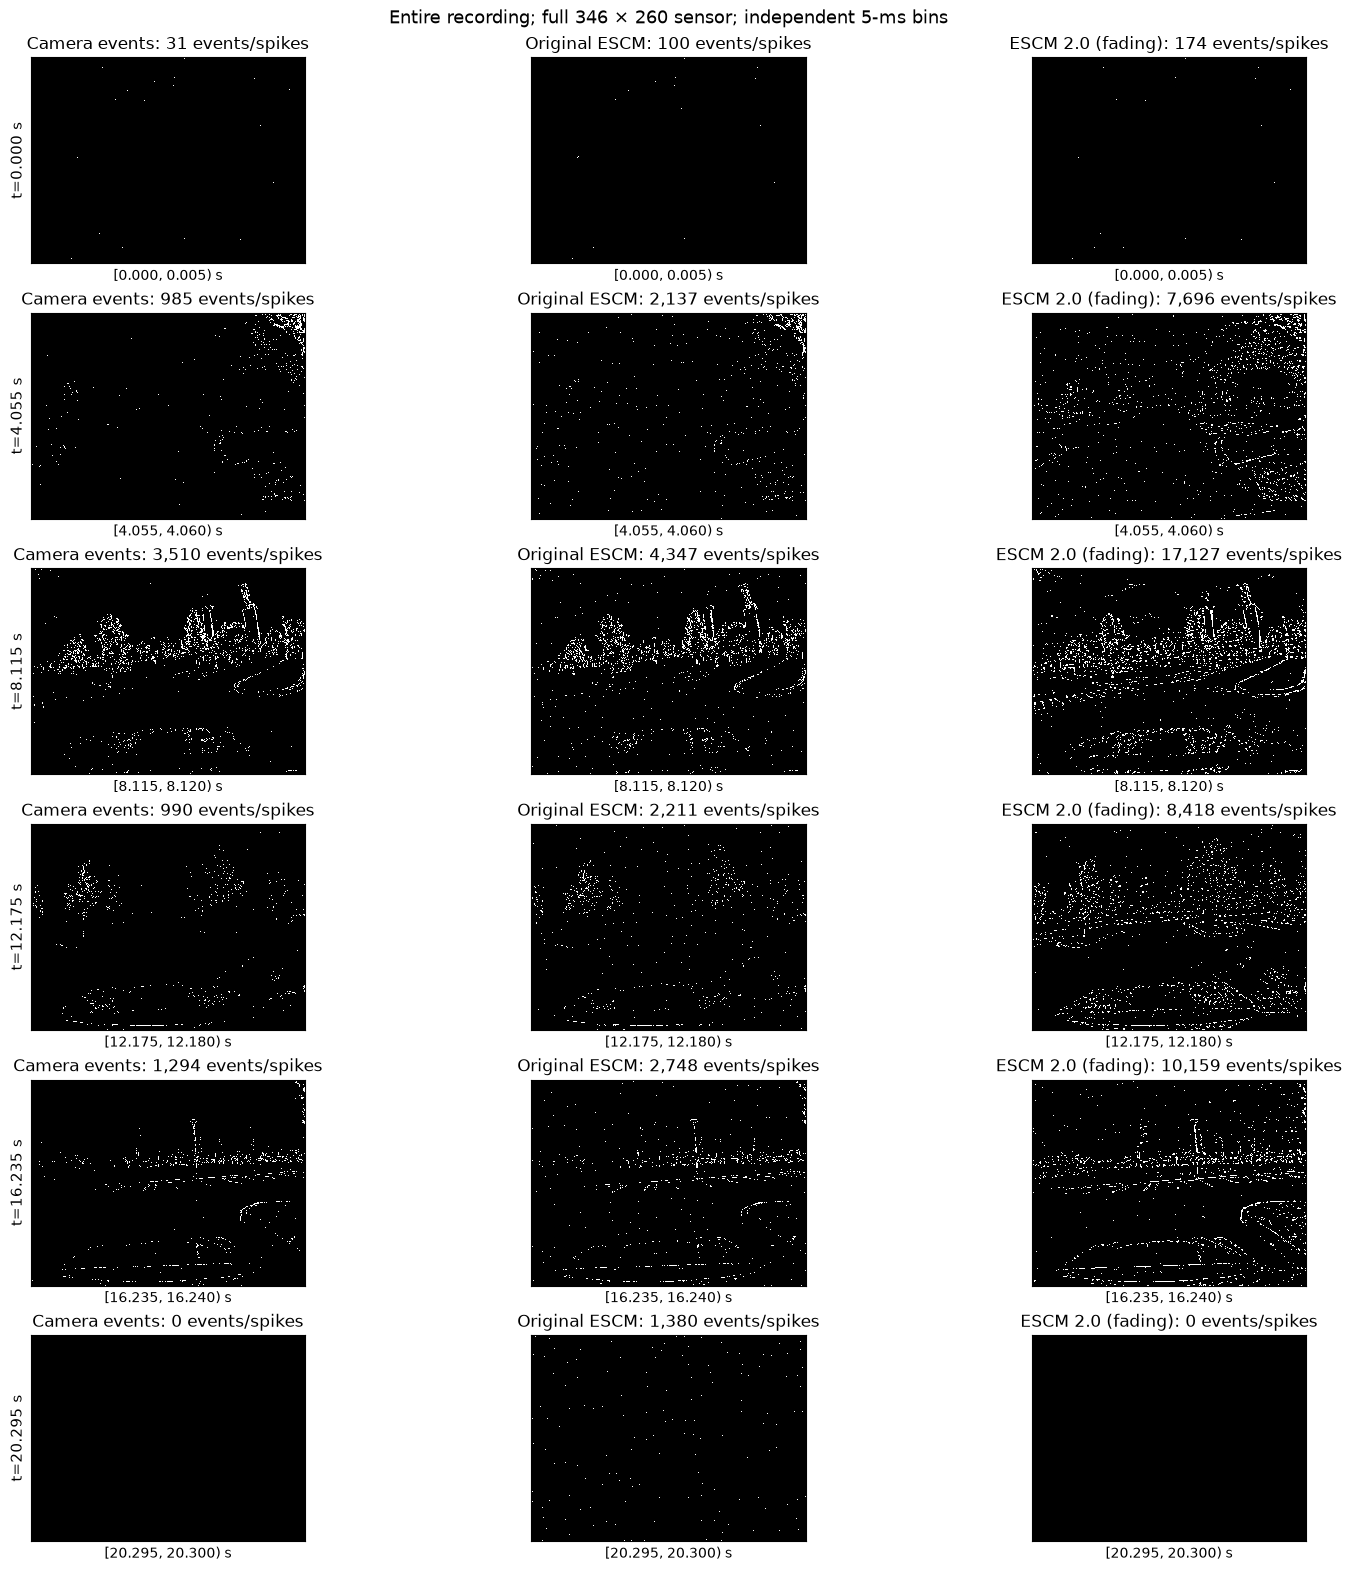

In [6]:
sample_frames = np.unique(np.linspace(0, len(frame_edges)-2, 6, dtype=int))
fig, axes = plt.subplots(len(sample_frames), 3, figsize=(15, 2.6*len(sample_frames)),
                         constrained_layout=True)
for row, k in enumerate(sample_frames):
    for col, name in enumerate(streams):
        ax = axes[row, col]
        arr = frame_counts(name, k)
        ax.imshow(arr > 0, cmap="gray", vmin=0, vmax=1,
                  interpolation="nearest", origin="upper")
        ax.set(title=f"{name}: {int(arr.sum()):,} events/spikes",
               xlabel=f"[{frame_edges[k]/1000:.3f}, {frame_edges[k+1]/1000:.3f}) s",
               xticks=[], yticks=[])
    axes[row, 0].set_ylabel(f"t={frame_edges[k]/1000:.3f} s", fontsize=11)
fig.suptitle("Entire recording; full 346 × 260 sensor; independent 5-ms bins", fontsize=13)
plt.show()


## 6. Verify persistence without consulting the visualization

Use the timestamp of the **last actual camera event** as the dividing line. For every stream, calculate the number of spikes strictly after this time and in the final 30 ms. Also count the number of distinct active output pixels.

This checks neural persistence directly from Brian2 SpikeMonitor data. It is independent of video generation. **Caution:** spikes immediately after the final camera event may still be a transient input response; reporting a late 30-ms window is stronger evidence of persistent firing than counting all tail spikes. Neither alone proves those pixels correspond to meaningful scene structure.

,stream,total_events,events_after_last_input,events_final_30_ms,active_pixels_final_30_ms
0,Camera events,7310278,0,0,0
1,Original ESCM,12525610,82955,8280,227
2,ESCM 2.0 (fading),45162602,46305,0,0


PASS: camera has zero events after the complete recording; later neural spikes are model outputs.


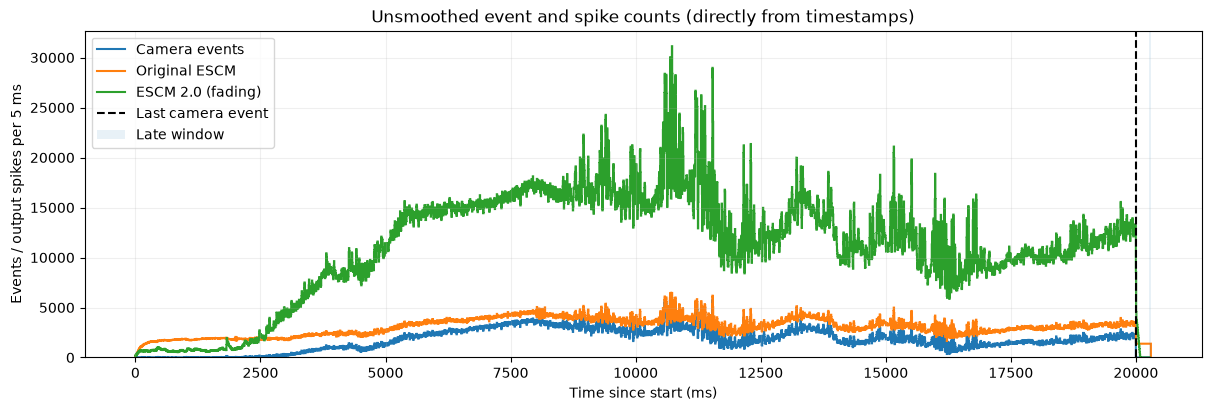

In [7]:
late_start_ms = simulation_duration_ms - 30.0
assert late_start_ms > input_duration_ms
rows = []
for name, (t, pixels) in streams.items():
    after_camera = t > last_input_ms
    late = (t >= late_start_ms) & (t < simulation_duration_ms)
    rows.append(dict(stream=name, total_events=len(t),
        events_after_last_input=int(after_camera.sum()),
        events_final_30_ms=int(late.sum()),
        active_pixels_final_30_ms=int(np.unique(pixels[late]).size)))
summary = pd.DataFrame(rows)
display(summary)
assert summary.iloc[0]["events_final_30_ms"] == 0
assert not np.any(frame_totals["Camera events"][frame_edges[:-1] >= input_duration_ms])
print("PASS: camera has zero events after the complete recording; later neural spikes are model outputs.")

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
for name, (t, _) in streams.items():
    ax.stairs(np.histogram(t, bins=frame_edges)[0], frame_edges,
              label=name, linewidth=1.5)
ax.axvline(last_input_ms, color="black", linestyle="--", label="Last camera event")
ax.axvspan(late_start_ms, simulation_duration_ms, alpha=0.1, label="Late window")
ax.set(xlabel="Time since start (ms)", ylabel="Events / output spikes per 5 ms",
       title="Unsmoothed event and spike counts (directly from timestamps)")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## 6A. Does self-excitation actually fade without new camera input?

The core hypothesis is not that the video becomes dark, but that the **SpikeMonitor records eventually stop producing spikes** after the final camera event. Each neuron's support trace follows

$$\mathrm{support}_i(t)=\mathrm{support}_i(t_i^{last})\exp[-(t-t_i^{last})/120\,\mathrm{ms}],$$

where $t_i^{last}$ is that pixel's last camera event. Thus, without further input, the maximal self-excitatory refresh decreases continuously, and recurrent spikes cannot replenish it. We report output counts in successive input-free windows, independently of rendering. A few initial spikes can be ordinary decay transients; a prolonged tail without input is the discriminating test.

**Prediction, not a pass condition:** with `W_E=8`, the refresh amplitude falls below 4 after $120\ln 2 \approx 83.2$ ms without camera input. The `W_E=4` criterion came from the earlier isolated-neuron analysis, so it is not a rigorous firing threshold for every inhibited neuron or firing phase. It is used here only for intuition.


,stream,silence_from_ms,silence_to_ms,spikes,active_pixels
0,Camera events,0,30,0,0
1,Camera events,30,60,0,0
2,Camera events,60,120,0,0
3,Camera events,120,180,0,0
4,Camera events,180,240,0,0
5,Camera events,240,300,0,0
6,Original ESCM,0,30,8435,336
7,Original ESCM,30,60,8280,227
8,Original ESCM,60,120,16560,227
9,Original ESCM,120,180,16560,227


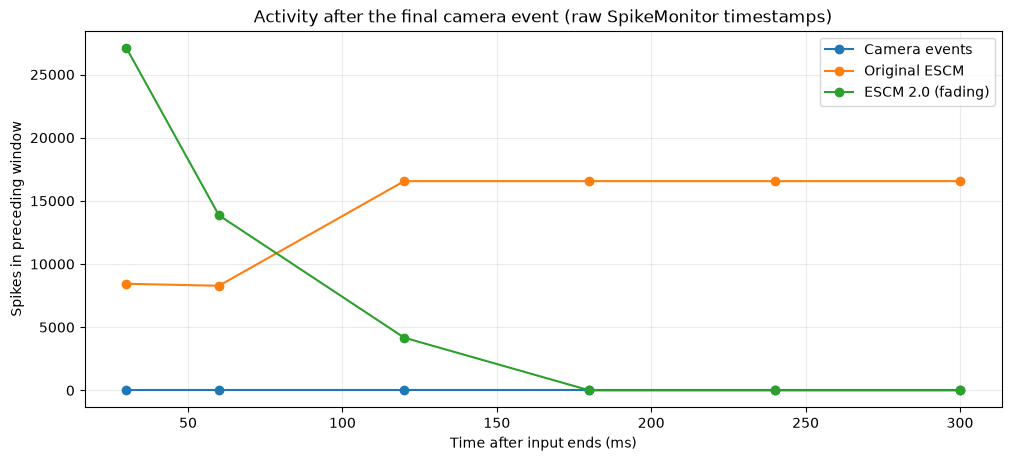

In [8]:
# Counts are computed from recorded spikes, never from rendered frames.
intervals = [(0, 30), (30, 60), (60, 120), (120, 180), (180, 240), (240, 300)]
fade_rows = []
for name, (times, pixels) in streams.items():
    for left, right in intervals:
        keep = (times >= input_duration_ms + left) & (times < input_duration_ms + right)
        fade_rows.append({"stream": name, "silence_from_ms": left,
                          "silence_to_ms": right,
                          "spikes": int(keep.sum()),
                          "active_pixels": int(np.unique(pixels[keep]).size)})
fade_table = pd.DataFrame(fade_rows)
display(fade_table)
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for name in streams:
    rows = fade_table[fade_table.stream == name]
    ax.plot(rows.silence_to_ms, rows.spikes, marker="o", label=name)
ax.set(xlabel="Time after input ends (ms)", ylabel="Spikes in preceding window",
       title="Activity after the final camera event (raw SpikeMonitor timestamps)")
ax.legend()
ax.grid(alpha=0.25)
plt.show()
# This verifies only the deterministic decay law, not the nonlinear spiking result.
assert np.isclose(np.exp(-120 / 120), np.exp(-1))
assert (fade_table[fade_table.stream == "Camera events"].spikes == 0).all()


## 7. Encode the *complete* recording as a synchronized three-panel video

The MP4 covers **every 5-ms interval** from the recording's first event through the last, plus a 300-ms silent-input tail. Frames are rendered individually from raw timestamp slices. We never reuse the prior frame's pixel map. A lossless PNG and the CSV count series provide independent reference checks without video compression.

**Playback time:** 5 ms of recorded time per frame, encoded at 30 fps. The video is slowed relative to real time so sparse events remain visible. Playback speed does *not* create persistent neuronal activity; every frame still represents only its own 5-ms timestamp window.


In [9]:
EXPORT_VIDEO = True
output_dir = root / "outputs" / "escm_comparison_sensory_fading_3panel"
output_dir.mkdir(parents=True, exist_ok=True)

frame_table = pd.DataFrame({"start_ms": frame_edges[:-1], "end_ms": frame_edges[1:]})
for name in streams:
    frame_table[name.replace(" ", "_").lower()] = frame_totals[name]
frame_table.to_csv(output_dir / "frame_counts.csv", index=False)

# A few lossless reference frames, independently reconstructed from timestamps.
for k in sample_frames:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for panel, name in zip(ax, streams):
        arr = frame_counts(name, k)
        panel.imshow(arr > 0, cmap="gray", vmin=0, vmax=1,
                     interpolation="nearest", origin="upper")
        panel.set(title=f"{name}: {int(arr.sum()):,}", xticks=[], yticks=[])
    fig.suptitle(f"Independent full-sensor frame [{frame_edges[k]/1000:.3f}, "
                 f"{frame_edges[k+1]/1000:.3f}) s")
    fig.savefig(output_dir / f"still_{k:06d}.png", dpi=160)
    plt.close(fig)

if EXPORT_VIDEO:
    import imageio.v2 as imageio
    video_path = output_dir / "camera_original_fading_full_recording.mp4"
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=110)
    artists = []
    for ax, name in zip(axes, streams):
        artist = ax.imshow(np.zeros((sensor_height, sensor_width)), cmap="gray",
                           vmin=0, vmax=1, interpolation="nearest", origin="upper")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(name)
        artists.append(artist)
    with imageio.get_writer(video_path, fps=30, codec="libx264", quality=9) as writer:
        for k in tqdm(range(len(frame_edges)-1), desc="Encode complete recording"):
            for artist, name in zip(artists, streams):
                artist.set_data(frame_counts(name, k) > 0)
            fig.suptitle(f"[{frame_edges[k]/1000:.3f}, {frame_edges[k+1]/1000:.3f}) s | "
                         f"counts: {', '.join(str(int(frame_totals[name][k])) for name in streams)}")
            fig.canvas.draw()
            writer.append_data(np.asarray(fig.canvas.buffer_rgba())[..., :3].copy())
    plt.close(fig)
    print("Saved complete recording video:", video_path)
print("Saved exact per-frame count CSV and lossless diagnostic stills:", output_dir)


Encode complete recording: 100%|██████████| 4060/4060 [01:32<00:00, 43.90it/s]


Saved complete recording video: /home/bmaacaron-iit.local/Documents/GitRepos/Event-SCM-Refactor/outputs/escm_comparison_sensory_fading_3panel/camera_original_fading_full_recording.mp4
Saved exact per-frame count CSV and lossless diagnostic stills: /home/bmaacaron-iit.local/Documents/GitRepos/Event-SCM-Refactor/outputs/escm_comparison_sensory_fading_3panel


## Interpretation and limitations

The three-panel video uses independent non-overlapping 5-ms bins. Both networks are simulated using Brian2 C++ standalone with separate generated projects; the reported native execution time excludes compilation. A pixel displayed in multiple output frames must have generated separate spikes in those windows; images do not retain pixels or blend neighboring frames. The additional 300-ms silent tail and raw-spike interval counts test whether firing eventually stops when camera input ceases.

**This experiment modifies ESCM 2.0's self-excitation rule.** It is no longer the frozen network evaluated in notebooks 18–22. That modification deliberately changes the theoretical goal from indefinitely persistent firing to a finite fading memory of camera activity. Suppression by a new edge is not demonstrated by simply observing eventual fading.

The experiment processes all canonicalized full-sensor events but instantiates only ever-stimulated neurons. This remains equivalent under these specific inhibitory-only lateral equations. Quantization collapses same-pixel same-tick events; the count is reported. The `tau_support` time constant is an **exploratory** value and must ultimately be assessed using temporal fidelity, not chosen solely to make video output look desirable.

**Status:** The notebook is not itself evidence of Brian2 execution. Its cells need to be run on the intended recording and installed Brian2 version.
